In [51]:
train_data= "../dataset/preprocessed/Training"
test_data= "../dataset/preprocessed/Testing"

In [52]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())

2.15.0+cu134
True


In [53]:
from torch.utils.data import Dataset
import os
from PIL import Image

class BTDataset(Dataset):
    def __init__(self, root, transform=None):
        self.transform = transform
        self.samples = []
        self.classes = sorted(os.listdir(root))

        for label, class_name in enumerate(self.classes):
            class_dir = os.path.join(root, class_name)
            if not os.path.isdir(class_dir):
                continue
            for image in os.listdir(class_dir):
                img_path = os.path.join(class_dir, image)
                # Load and resize once into RAM (~367 MB total)
                img = Image.open(img_path).convert("L").resize((224, 224))
                self.samples.append((img, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img, label = self.samples[idx]
        if self.transform:
            img = self.transform(img)
        return img, label


In [54]:
from torchvision import transforms

train_transform= transforms.Compose([
    transforms.Grayscale(1),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(
        0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean= [0.183], std= [0.200])
    # transforms.Normalize(
    #     mean= [0.18395672, 0.18395881, 0.18399635],
    #     std= [0.20059544, 0.20059426, 0.20062249])
])

val_transform= transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean= [0.183], std= [0.200])
    # transforms.Normalize(
    #     mean= [0.18395672, 0.18395881, 0.18399635],
    #     std= [0.20059544, 0.20059426, 0.20062249])
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean= [0.183], std= [0.200])
    # transforms.Normalize(
    #     mean=[0.18395672, 0.18395881, 0.18399635],
    #     std=[0.20059544, 0.20059426, 0.20062249])
])

In [55]:
train_dataset= BTDataset(train_data, transform= train_transform)
val_dataset= BTDataset(train_data, transform= val_transform)
test_dataset = BTDataset(test_data, transform=test_transform)

In [56]:
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

5600
5600
1600


In [57]:
from torch.utils.data import random_split

total_size= len(train_dataset)
train_size = int(total_size * 0.9)
val_size= total_size- train_size

generator= torch.Generator().manual_seed(42)

train_split, val_split= random_split(
    train_dataset,
    [train_size, val_size],
    generator= generator
)

In [58]:
from torch.utils.data import Subset

train_subset= Subset(
    train_dataset,
    train_split.indices
)

val_subset= Subset(
    val_dataset,
    val_split.indices
)

In [59]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    dataset=train_subset,
    batch_size=64,
    shuffle=True,
    num_workers=0,           # Use 2 on Colab/Kaggle, or 4–8 on a local multi-core PC
    pin_memory=True
)

val_loader = DataLoader(
    dataset=val_subset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


In [60]:
print(len(train_split))
print(len(val_split))
print(len(test_dataset))

5040
560
1600


In [61]:
import torch.nn as nn

def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        nn.Conv2d(cout, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        nn.MaxPool2d(2, 2)
    )

class BTCCnn(nn.Module):
    def __init__(self, num_classes=4, in_ch=1):
        super(BTCCnn, self).__init__()

        self.features = nn.Sequential(
            conv_block(in_ch, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
            conv_block(256, 512),
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

model = BTCCnn(num_classes=4, in_ch=1)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameters: {n_params:,}")

Parameters: 4,878,372


In [62]:
device= torch.device("cuda" if torch.cuda.is_available() else "cpu")
model= model.to(device)
torch.backends.cudnn.benchmark = True
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer= torch.optim.Adam(
    model.parameters(), lr= 0.001
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer=optimizer,
    step_size=5,
    gamma=0.5
)

In [63]:
def train_one_epoch(model, data_loader, device, optimizer, criterion):
    model.train()

    train_loss = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predicted = torch.argmax(outputs, dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = train_loss / total
    train_acc = 100 * correct / total
    return avg_loss, train_acc

def evaluate(model, data_loader, device, criterion):
    model.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predicted = torch.argmax(outputs, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_val_loss = val_loss / total
    val_acc = 100 * correct / total

    return avg_val_loss, val_acc

In [64]:
class EarlyStopping:
    def __init__(self, patience= 7, min_delta= 0):
        self.patience= patience
        self.min_delta= min_delta
        self.counter= 0
        self.best_loss= float("inf")
        self.early_stop= False
    def __call__(self, val_loss):
        if val_loss < self.best_loss- self.min_delta:
            self.best_loss= val_loss
            self.counter= 0
            os.makedirs("../models/checkpoints", exist_ok=True)
            torch.save(model.state_dict(), "../models/checkpoints/best_model.pth")
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop= True

In [65]:
early_stopping = EarlyStopping(patience=7, min_delta=0.001)
epochs= 30

t_losses, t_accs = [], []
v_losses, v_accs = [], []

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, device, optimizer, criterion)
    val_loss, val_acc = evaluate(model, val_loader, device, criterion)
    t_losses.append(train_loss)
    t_accs.append(train_acc)
    v_losses.append(val_loss)
    v_accs.append(val_acc)

    scheduler.step()
    early_stopping(val_loss)

    print(f"Epoch {epoch+1}/{epochs} -> Train Loss: {train_loss:.2f}, Acc: {train_acc:.2f}% | Val Loss: {val_loss:.2f}, Acc: {val_acc:.2f}%")

    if early_stopping.early_stop:
        print(f"Early stopping triggered at epoch {epoch+1}")
        break

Epoch 1/30 -> Train Loss: 0.98, Acc: 64.27% | Val Loss: 2.87, Acc: 32.68%
Epoch 2/30 -> Train Loss: 0.81, Acc: 75.83% | Val Loss: 0.89, Acc: 71.96%
Epoch 3/30 -> Train Loss: 0.75, Acc: 80.08% | Val Loss: 1.26, Acc: 58.93%
Epoch 4/30 -> Train Loss: 0.73, Acc: 81.63% | Val Loss: 0.76, Acc: 78.75%
Epoch 5/30 -> Train Loss: 0.68, Acc: 84.66% | Val Loss: 0.74, Acc: 78.75%
Epoch 6/30 -> Train Loss: 0.63, Acc: 86.69% | Val Loss: 0.63, Acc: 86.07%
Epoch 7/30 -> Train Loss: 0.62, Acc: 87.32% | Val Loss: 0.61, Acc: 87.14%
Epoch 8/30 -> Train Loss: 0.60, Acc: 88.15% | Val Loss: 0.61, Acc: 86.25%
Epoch 9/30 -> Train Loss: 0.58, Acc: 89.09% | Val Loss: 0.56, Acc: 89.46%
Epoch 10/30 -> Train Loss: 0.56, Acc: 90.28% | Val Loss: 0.54, Acc: 89.46%
Epoch 11/30 -> Train Loss: 0.54, Acc: 91.51% | Val Loss: 0.57, Acc: 88.57%
Epoch 12/30 -> Train Loss: 0.53, Acc: 92.12% | Val Loss: 0.52, Acc: 91.43%
Epoch 13/30 -> Train Loss: 0.53, Acc: 92.08% | Val Loss: 0.51, Acc: 92.50%
Epoch 14/30 -> Train Loss: 0.50, A

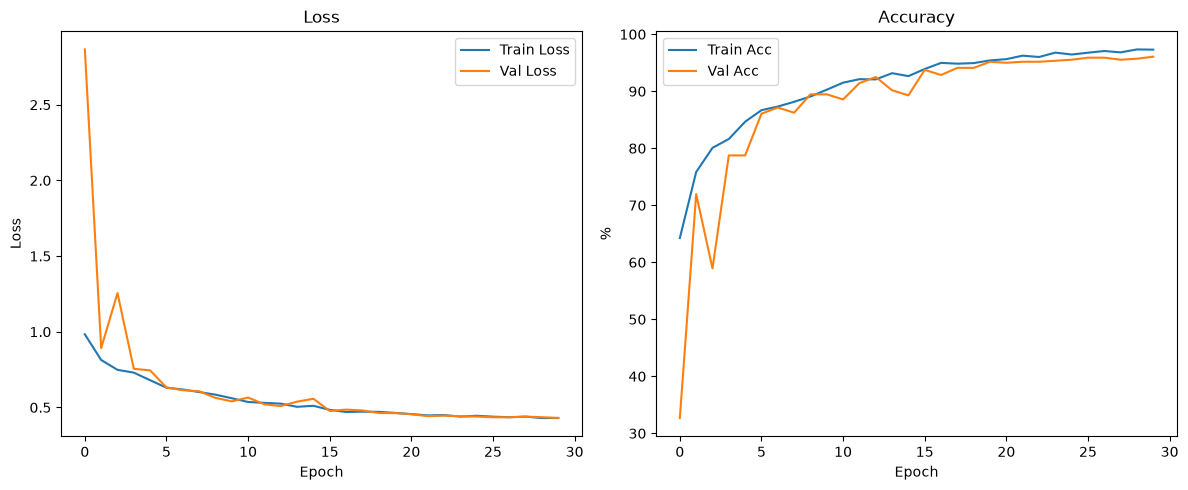

In [66]:
import matplotlib.pyplot as plt

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 5))

ax_left.plot(t_losses, label="Train Loss")
ax_left.plot(v_losses, label="Val Loss")
ax_left.set_title("Loss")
ax_left.set_xlabel("Epoch")
ax_left.set_ylabel("Loss")
ax_left.legend()

ax_right.plot(t_accs, label="Train Acc")
ax_right.plot(v_accs, label="Val Acc")
ax_right.set_title("Accuracy")
ax_right.set_xlabel("Epoch")
ax_right.set_ylabel("%")
ax_right.legend()

plt.tight_layout()
plt.savefig("../outputs/plots/model_training.png")
plt.show()

In [67]:
model.load_state_dict(torch.load("../models/checkpoints/best_model.pth", map_location=device, weights_only=True))
model.to(device)

BTCCnn(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU

In [68]:
test_loss, test_acc = evaluate(model, test_loader, device, criterion)
print(f"Test Loss: {test_loss:.2f} | Test Acc: {test_acc:.2f}%")

Test Loss: 0.54 | Test Acc: 92.19%


In [69]:
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predicted = torch.argmax(outputs, dim=1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

In [70]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, ConfusionMatrixDisplay

In [71]:
print(classification_report(all_labels, all_preds, target_names= train_dataset.classes))

              precision    recall  f1-score   support

      glioma       0.99      0.78      0.87       400
  meningioma       0.91      0.91      0.91       400
     notumor       0.87      1.00      0.93       400
   pituitary       0.94      1.00      0.97       400

    accuracy                           0.92      1600
   macro avg       0.93      0.92      0.92      1600
weighted avg       0.93      0.92      0.92      1600



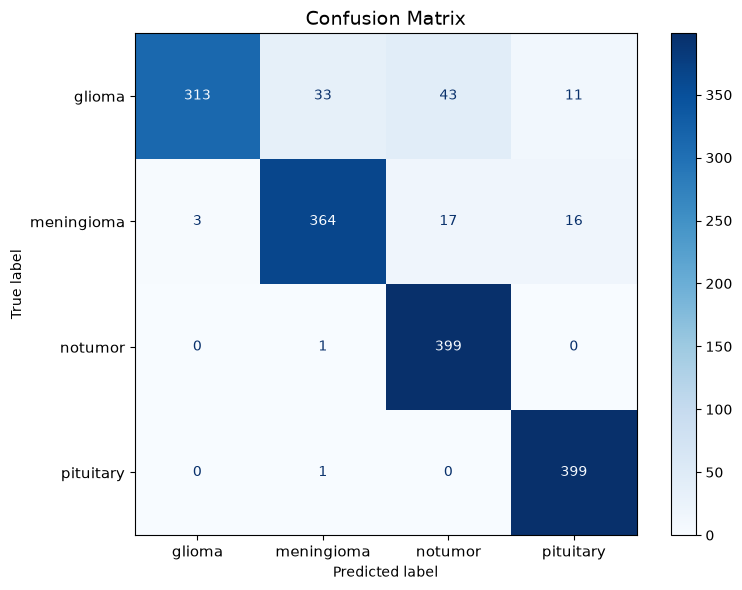

In [72]:
fig, ax = plt.subplots(figsize=(8, 6))  # Increase to (10, 8) if you want it even larger

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=train_dataset.classes)
disp.plot(cmap="Blues", ax=ax, values_format="d")  # 'd' keeps numbers as clean integers

plt.title("Confusion Matrix", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.savefig("../outputs/plots/confusion_matrix.png")
plt.show()


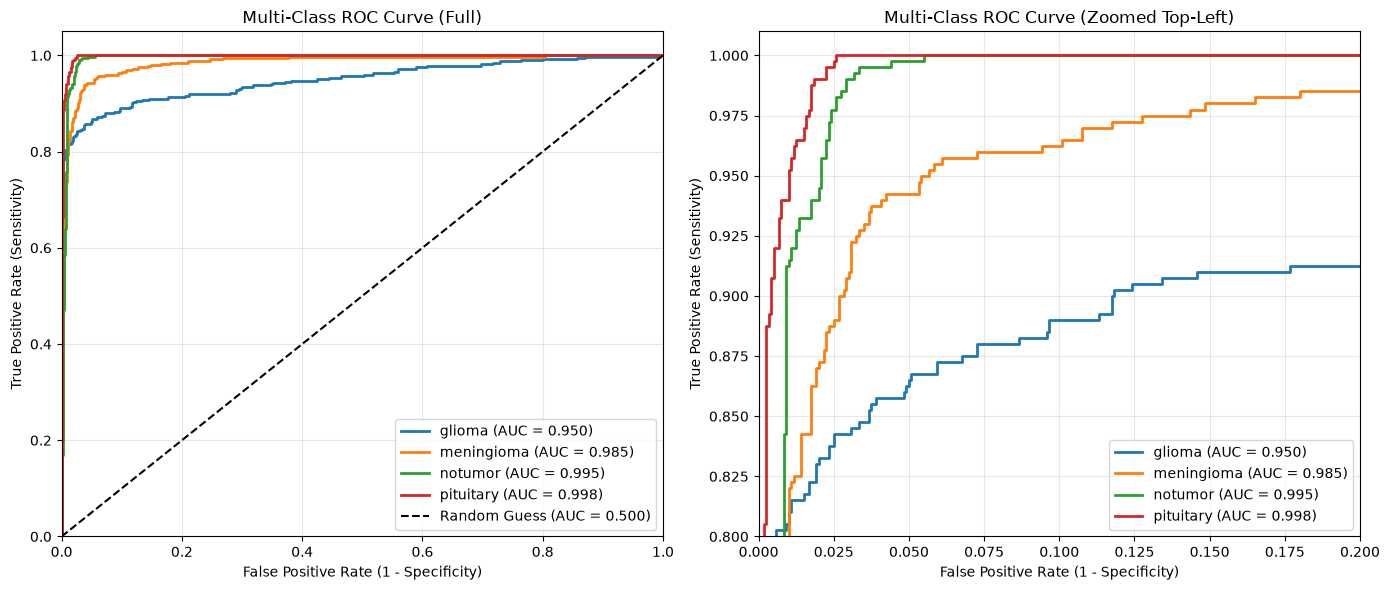

In [73]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. Collect true labels and predicted probabilities from the test set
model.eval()
y_true = []
y_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_probs.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_probs = np.array(y_probs)
class_names = test_dataset.classes
n_classes = len(class_names)

# 2. Binarize labels for One-vs-Rest multi-class ROC
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# 3. Create side-by-side plots (Full + Zoomed)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_auc = auc(fpr, tpr)
    label = f"{class_names[i]} (AUC = {roc_auc:.3f})"

    ax1.plot(fpr, tpr, lw=2, label=label)
    ax2.plot(fpr, tpr, lw=2, label=label)

# Left subplot: Full ROC Curve
ax1.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random Guess (AUC = 0.500)")
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Sensitivity)")
ax1.set_title("Multi-Class ROC Curve (Full)")
ax1.legend(loc="lower right")
ax1.grid(alpha=0.3)

# Right subplot: Zoomed Top-Left Corner
ax2.set_xlim([0.0, 0.2])
ax2.set_ylim([0.8, 1.01])
ax2.set_xlabel("False Positive Rate (1 - Specificity)")
ax2.set_ylabel("True Positive Rate (Sensitivity)")
ax2.set_title("Multi-Class ROC Curve (Zoomed Top-Left)")
ax2.legend(loc="lower right")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/plots/roc_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


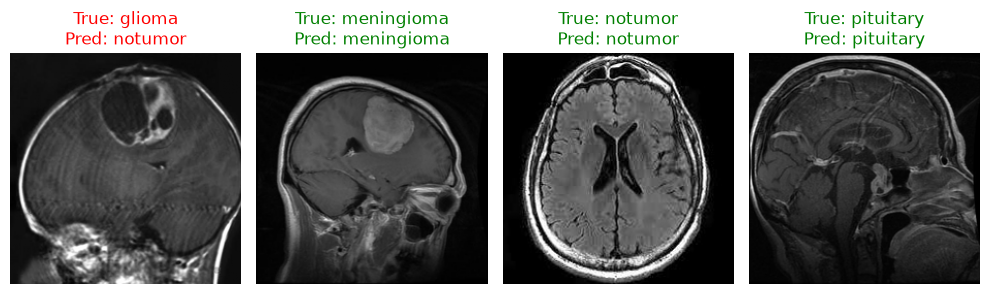

In [174]:
import random
from PIL import Image

class_names= train_dataset.classes
plt.figure(figsize=(10, 10))

for i, class_name in enumerate(os.listdir(test_data)):
    class_folder= os.path.join(test_data, class_name)
    random_img= random.choice(os.listdir(class_folder))
    img_path= os.path.join(class_folder, random_img)

    img= Image.open(img_path).convert("L").resize((224, 224))
    img= test_transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        outputs= model(img)
        predicted = torch.argmax(outputs, dim = 1)
        predicted_label = class_names[predicted.item()]
        color = "green" if predicted_label == class_name else "red"

        plt.subplot(2, 4, i+1)
        plt.imshow(img.squeeze().cpu(), cmap="gray")
        plt.title(f"True: {class_name}\nPred: {predicted_label}", color=color)
        plt.axis("off")
plt.tight_layout()
plt.savefig("../outputs/predictions/predictions.png")
plt.show()